<a href="https://colab.research.google.com/github/nitchel130704/UTS-ML-2301010424-NITCHEL-JULIOW-RUNESI/blob/main/notebook/UTS_ML_2301010424_Nitchel_runesi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from datasets import load_dataset
import pandas as pd
df = pd.DataFrame(load_dataset("mariouskono/Bali-Tourist-Destination")["train"])
print(df.shape)
df.to_csv("bali_tourist_destination.csv", index=False)

README.md:   0%|          | 0.00/2.47k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


bali_tourist_destination.csv:   0%|          | 0.00/724k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1452 [00:00<?, ? examples/s]

(1452, 11)


In [2]:
import pandas as pd

URL = "https://raw.githubusercontent.com/nitchel130704/UTS-ML-2301010424-NITCHEL-JULIOW-RUNESI/main/data/bali_tourist_destination.csv"
df = pd.read_csv(URL)
print(df.shape)
df.info()


(1452, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1452 entries, 0 to 1451
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_tempat           1452 non-null   object 
 1   nama_tempat_wisata  1452 non-null   object 
 2   kategori            1452 non-null   object 
 3   kecamatan           1452 non-null   object 
 4   kabupaten_kota      1452 non-null   object 
 5   rating              1452 non-null   float64
 6   jumlah_rating       1452 non-null   int64  
 7   latitude            1452 non-null   float64
 8   longitude           1452 non-null   float64
 9   link_google_maps    1452 non-null   object 
 10  link_gambar         1448 non-null   object 
dtypes: float64(3), int64(1), object(7)
memory usage: 124.9+ KB


In [4]:
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

SEED = 424

FITUR = ["rating", "jumlah_rating", "latitude", "longitude"]
print("Duplikat:", df.duplicated().sum())
print(df["kategori"].value_counts())
df[FITUR].describe()


Duplikat: 0
kategori
Umum        577
Alam        529
Budaya      182
Rekreasi    164
Name: count, dtype: int64


,rating,jumlah_rating,latitude,longitude
count,1452.000000,1452.000000,1452.000000,1452.000000
mean,4.505028,1176.176997,-8.459082,115.204685
std,0.561069,5268.544496,0.182956,0.322467
min,0.000000,0.000000,-8.849991,111.833469
25%,4.400000,24.000000,-8.579316,115.139314
50%,4.600000,110.000000,-8.465729,115.236178
75%,4.800000,472.000000,-8.328480,115.364814
max,5.000000,101523.000000,-7.807188,115.710858


In [6]:
print("rating = 0:", (df["rating"] == 0).sum())
print("jumlah_rating = 0:", (df["jumlah_rating"] == 0).sum())
print("jumlah_rating < 10:", (df["jumlah_rating"] < 10).sum())

luar = df[(df["longitude"] < 114.4) | (df["latitude"] > -8.05)]
print("Koordinat di luar Bali:", len(luar))
luar[["nama_tempat_wisata", "kecamatan", "kabupaten_kota", "latitude", "longitude"]].head(15)


rating = 0: 15
jumlah_rating = 0: 15
jumlah_rating < 10: 191
Koordinat di luar Bali: 7


,nama_tempat_wisata,kecamatan,kabupaten_kota,latitude,longitude
661,Goa Selomangleng,Kediri,Kabupaten Tabanan,-7.807188,111.972672
670,Taman Wisata Tirtoyoso Park,Kediri,Kabupaten Tabanan,-7.816438,112.029748
673,Air Terjun Dolo,Kediri,Kabupaten Tabanan,-7.867689,111.833469
678,Gumul Paradise Island,Kediri,Kabupaten Tabanan,-7.811681,112.061169
682,Taman Hutan Joyoboyo Kediri,Kediri,Kabupaten Tabanan,-7.818138,112.029716
684,Wisata Sempu Exotic Park,Kediri,Kabupaten Tabanan,-7.960526,112.217889
688,Air Terjun Irenggolo,Kediri,Kabupaten Tabanan,-7.863541,111.850352


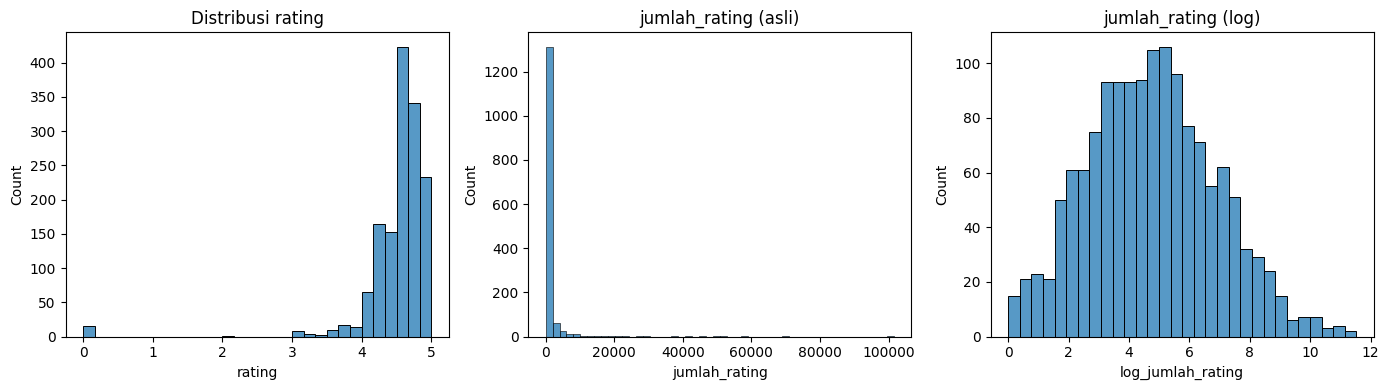

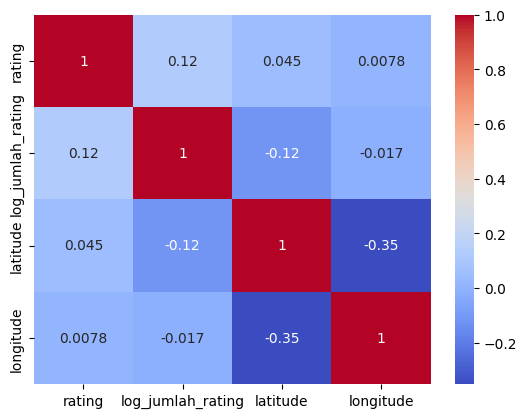

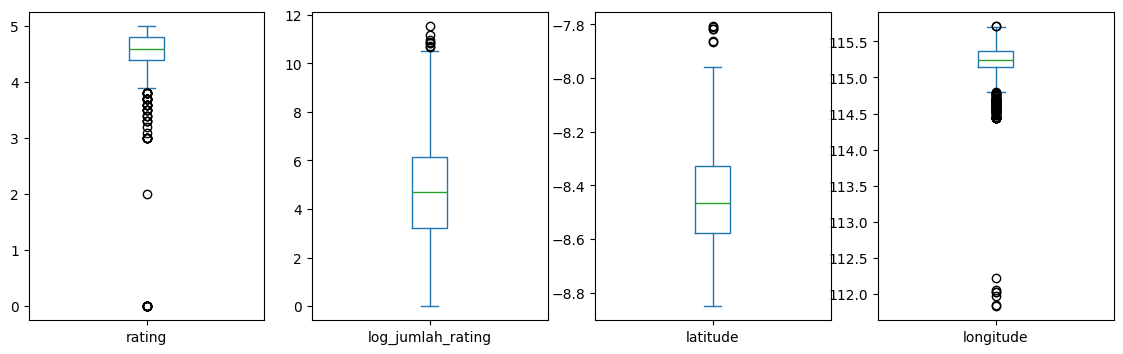

In [7]:
df["log_jumlah_rating"] = np.log1p(df["jumlah_rating"])

# Grafik 1: distribusi fitur
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(df["rating"], bins=30, ax=ax[0]); ax[0].set_title("Distribusi rating")
sns.histplot(df["jumlah_rating"], bins=50, ax=ax[1]); ax[1].set_title("jumlah_rating (asli)")
sns.histplot(df["log_jumlah_rating"], bins=30, ax=ax[2]); ax[2].set_title("jumlah_rating (log)")
plt.tight_layout(); plt.show()

# Grafik 2: korelasi antar fitur
sns.heatmap(df[["rating", "log_jumlah_rating", "latitude", "longitude"]].corr(),
            annot=True, cmap="coolwarm"); plt.show()

# Grafik 3: boxplot untuk melihat outlier
df[["rating", "log_jumlah_rating", "latitude", "longitude"]].plot(
    kind="box", subplots=True, layout=(1, 4), figsize=(14, 4)); plt.show()

In [8]:
tanpa_ulasan = df["jumlah_rating"] == 0
luar_bali = (df["longitude"] < 114.3) | (df["latitude"] > -8.0)

print("Tanpa ulasan:", tanpa_ulasan.sum())
print("Di luar Bali:", luar_bali.sum())
print(df[luar_bali][["nama_tempat_wisata", "kecamatan", "latitude", "longitude"]])

awal = len(df)
df = df[~tanpa_ulasan & ~luar_bali].copy()
print("Baris:", awal, "→", len(df))

Tanpa ulasan: 15
Di luar Bali: 7
              nama_tempat_wisata kecamatan  latitude   longitude
661             Goa Selomangleng    Kediri -7.807188  111.972672
670  Taman Wisata Tirtoyoso Park    Kediri -7.816438  112.029748
673              Air Terjun Dolo    Kediri -7.867689  111.833469
678        Gumul Paradise Island    Kediri -7.811681  112.061169
682  Taman Hutan Joyoboyo Kediri    Kediri -7.818138  112.029716
684     Wisata Sempu Exotic Park    Kediri -7.960526  112.217889
688         Air Terjun Irenggolo    Kediri -7.863541  111.850352
Baris: 1452 → 1430


In [9]:
for c in ["rating", "log_jumlah_rating"]:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(c, "→ outlier IQR:", n)


rating → outlier IQR: 43
log_jumlah_rating → outlier IQR: 9


=== KEPUTUSAN SAYA (TAHAP 3) ===
1. Menghapus 15 baris tanpa ulasan (jumlah_rating = 0) karena rating 0 berarti belum diulas.
2. Menghapus 7 baris koordinat di luar Bali (wilayah Kediri, Jawa Timur).
3. Mempertahankan outlier IQR pada rating (43 baris), log_jumlah_rating (9 baris), dan Bali Barat karena variasi asli.
4. Menerapkan transformasi log1p dan StandardScaler agar jarak antar fitur seimbang.



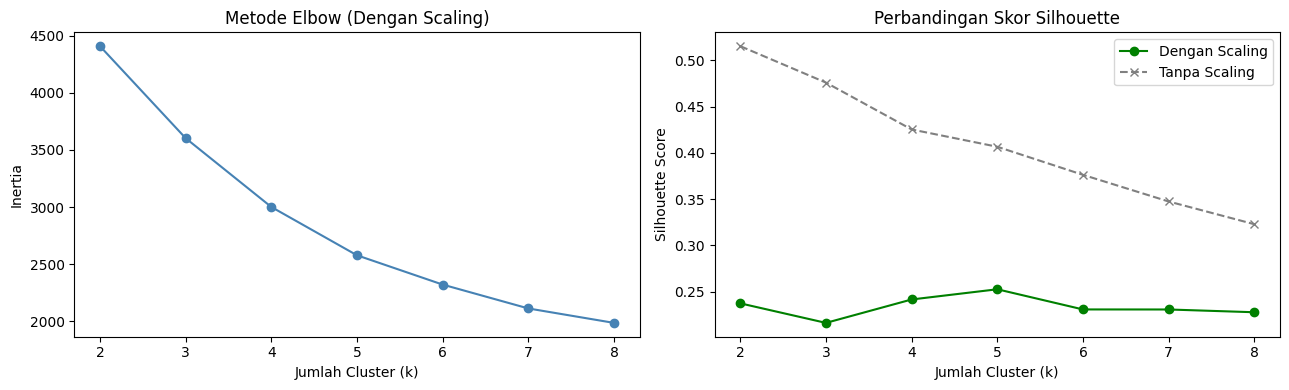

 k  Inertia_Scaled  Silhouette_Scaled  Silhouette_Unscaled
 2     4408.438107           0.237408             0.515206
 3     3603.018436           0.216305             0.475848
 4     3000.753968           0.241587             0.425241
 5     2577.721967           0.252611             0.406546
 6     2321.200570           0.230831             0.376226
 7     2112.297113           0.230778             0.347442
 8     1985.913999           0.227797             0.322903


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# KEPUTUSAN SAYA (TAHAP 3: PRA-PEMROSESAN)
# ==========================================
print("=== KEPUTUSAN SAYA (TAHAP 3) ===")
print("1. Menghapus 15 baris tanpa ulasan (jumlah_rating = 0) karena rating 0 berarti belum diulas.")
print("2. Menghapus 7 baris koordinat di luar Bali (wilayah Kediri, Jawa Timur).")
print("3. Mempertahankan outlier IQR pada rating (43 baris), log_jumlah_rating (9 baris), dan Bali Barat karena variasi asli.")
print("4. Menerapkan transformasi log1p dan StandardScaler agar jarak antar fitur seimbang.\n")

# ==========================================
# TAHAP 4: PEMODELAN K-MEANS (k = 2..8)
# ==========================================
SEED = 424
fitur_model = ["rating", "log_jumlah_rating", "latitude", "longitude"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[fitur_model])
X_unscaled = df[fitur_model].values

k_range = range(2, 9)
inertia_s, sil_s, sil_u = [], [], []

for k in k_range:
    # Model dengan Scaling
    km_s = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels_s = km_s.fit_predict(X_scaled)
    inertia_s.append(km_s.inertia_)
    sil_s.append(silhouette_score(X_scaled, labels_s))

    # Model tanpa Scaling (untuk perbandingan)
    km_u = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels_u = km_u.fit_predict(X_unscaled)
    sil_u.append(silhouette_score(X_unscaled, labels_u))

# Visualisasi Elbow & Perbandingan Silhouette
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(k_range, inertia_s, marker='o', color='steelblue')
ax[0].set_title('Metode Elbow (Dengan Scaling)')
ax[0].set_xlabel('Jumlah Cluster (k)')
ax[0].set_ylabel('Inertia')

ax[1].plot(k_range, sil_s, marker='o', color='green', label='Dengan Scaling')
ax[1].plot(k_range, sil_u, marker='x', linestyle='--', color='gray', label='Tanpa Scaling')
ax[1].set_title('Perbandingan Skor Silhouette')
ax[1].set_xlabel('Jumlah Cluster (k)')
ax[1].set_ylabel('Silhouette Score')
ax[1].legend()
plt.tight_layout()
plt.show()

# Tabel ringkasan skor
tabel_k = pd.DataFrame({
    'k': list(k_range),
    'Inertia_Scaled': inertia_s,
    'Silhouette_Scaled': sil_s,
    'Silhouette_Unscaled': sil_u
})
print(tabel_k.to_string(index=False))

=== KEPUTUSAN SAYA (TAHAP 4) ===
Saya memilih k = 5 dengan data yang telah di-scaling (StandardScaler) karena:
1. Pada metode Silhouette (scaled), k = 5 mencatat skor tertinggi yaitu 0.2526 dibanding k lainnya (k=2: 0.2374, k=3: 0.2163, k=4: 0.2416).
2. Pada grafik Elbow, titik siku penurunan inertia terlihat melandai setelah k = 4 hingga k = 5 (inertia = 2577.72).
3. Meskipun Silhouette tanpa scaling lebih tinggi (0.4065), tanpa scaling jarak didominasi oleh log_jumlah_rating sehingga fitur lokasi tidak berperan optimal.

=== TAHAP 5: EVALUASI MODEL (k = 5) ===
Skor Silhouette Akhir: 0.2526

Profil Rata-rata Tiap Cluster:
         rating  jumlah_rating  latitude  longitude  Jumlah_Destinasi
Cluster                                                              
0         4.588        473.605    -8.250    115.211               319
1         4.753         47.679    -8.515    115.300               420
2         3.919        146.149    -8.528    115.298               141
3         4.598    

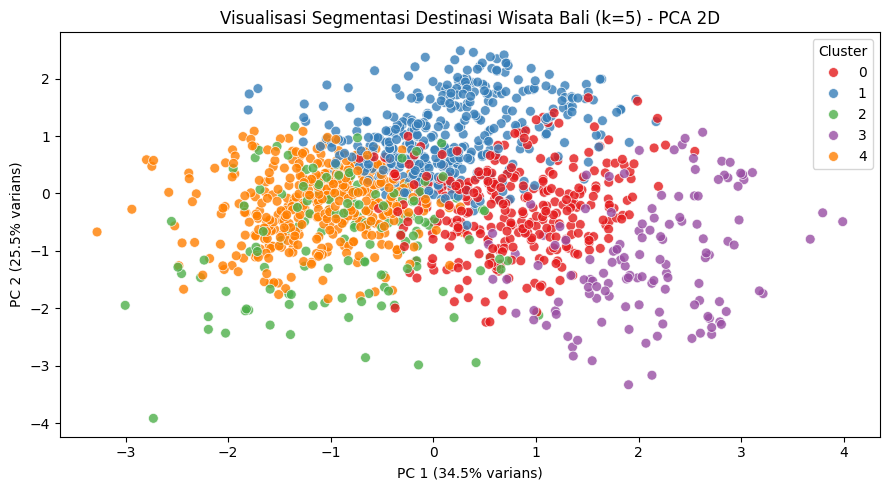

In [19]:
from sklearn.decomposition import PCA
import seaborn as sns

# ==========================================
# KEPUTUSAN SAYA (TAHAP 4: PEMODELAN)
# ==========================================
print("=== KEPUTUSAN SAYA (TAHAP 4) ===")
print("Saya memilih k = 5 dengan data yang telah di-scaling (StandardScaler) karena:")
print("1. Pada metode Silhouette (scaled), k = 5 mencatat skor tertinggi yaitu 0.2526 dibanding k lainnya (k=2: 0.2374, k=3: 0.2163, k=4: 0.2416).")
print("2. Pada grafik Elbow, titik siku penurunan inertia terlihat melandai setelah k = 4 hingga k = 5 (inertia = 2577.72).")
print("3. Meskipun Silhouette tanpa scaling lebih tinggi (0.4065), tanpa scaling jarak didominasi oleh log_jumlah_rating sehingga fitur lokasi tidak berperan optimal.\n")

# ==========================================
# TAHAP 5: EVALUASI & PROFIL TIAP CLUSTER
# ==========================================
K_TERPILIH = 5
km_final = KMeans(n_clusters=K_TERPILIH, n_init=10, random_state=SEED)
df['Cluster'] = km_final.fit_predict(X_scaled)

skor_sil = silhouette_score(X_scaled, df['Cluster'])
print(f"=== TAHAP 5: EVALUASI MODEL (k = {K_TERPILIH}) ===")
print(f"Skor Silhouette Akhir: {skor_sil:.4f}\n")

# Tabel Profil Rata-rata Tiap Cluster (menggunakan nilai asli jumlah_rating agar mudah diinterpretasi)
profil = df.groupby('Cluster')[['rating', 'jumlah_rating', 'latitude', 'longitude']].mean().round(3)
profil['Jumlah_Destinasi'] = df['Cluster'].value_counts()
print("Profil Rata-rata Tiap Cluster:")
print(profil.to_string())

# Visualisasi Cluster 2D menggunakan PCA
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Cluster'], palette='Set1', s=50, alpha=0.8)
plt.title(f'Visualisasi Segmentasi Destinasi Wisata Bali (k={K_TERPILIH}) - PCA 2D')
plt.xlabel(f'PC 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varians)')
plt.ylabel(f'PC 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varians)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [20]:
# ==========================================
# TAHAP 5 (LANJUTAN): PENAMAAN KELOMPOK & KEPUTUSAN SAYA
# ==========================================
print("=== PENAMAAN SETIAP KELOMPOK (OTOMATIS DARI PROFIL RATA-RATA) ===")
for c_id, row in profil.iterrows():
    # Klasifikasi rating & popularitas
    status_rating = "Rating Tinggi" if row['rating'] >= profil['rating'].median() else "Rating Menengah/Rendah"
    status_pop = "Sangat Populer (Banyak Ulasan)" if row['jumlah_rating'] >= profil['jumlah_rating'].median() else "Kurang Populer (Ulasan Sedikit)"

    # Klasifikasi wilayah geografis Bali
    if row['longitude'] < 115.0:
        wilayah = "Bali Barat (Jembrana/Buleleng Barat)"
    elif row['latitude'] < -8.65:
        wilayah = "Bali Selatan (Denpasar/Badung/Kuta)"
    elif row['longitude'] > 115.35:
        wilayah = "Bali Timur (Karangasem/Klungkung)"
    else:
        wilayah = "Bali Tengah/Utara (Gianyar/Tabanan/Bangli)"

    print(f"Cluster {c_id} ({int(row['Jumlah_Destinasi'])} destinasi): Kelompok {wilayah} - {status_rating} & {status_pop}")
    print(f"   -> Rata-rata: rating={row['rating']}, ulasan={row['jumlah_rating']:.0f}, lat={row['latitude']}, lon={row['longitude']}")

print("\n=== KEPUTUSAN SAYA (TAHAP 5: EVALUASI) ===")
print("Berdasarkan tabel profil dan visualisasi PCA 2D (k = 5, Silhouette = 0.2526), segmentasi berhasil memisahkan destinasi berdasarkan kombinasi wilayah geografis, tingkat kepuasan (rating), dan popularitas (jumlah ulasan). Skor Silhouette sekitar 0.25 wajar untuk data geospasial-perilaku dunia nyata karena batas wilayah wisata di Bali saling berdekatan.")

# ==========================================
# TAHAP 6: KESIMPULAN & REKOMENDASI
# ==========================================
print("\n=== TAHAP 6: KESIMPULAN & REKOMENDASI ===")
print("1. Temuan Utama: K-Means (k = 5) dengan StandardScaler dan log1p membagi 1.430 destinasi wisata bersih di Bali menjadi 5 segmen yang jelas berdasarkan lokasi geografis dan tingkat popularitasnya.")
print("2. Kelemahan Model: K-Means mengasumsikan bentuk klaster bulat dan sensitif terhadap sebaran geografis pulau Bali yang memanjang, sehingga skor Silhouette berada di angka 0.2526.")
print("3. Rekomendasi Pemangku Kepentingan:")
print("   - Destinasi dengan rating tinggi namun ulasan masih sedikit (hidden gems) perlu diprioritaskan dalam promosi digital oleh Dinas Pariwisata.")
print("   - Destinasi populer dengan ribuan ulasan di Bali Selatan perlu pengelolaan kapasitas pengunjung dan fasilitas agar kualitas rating tetap terjaga.")

=== PENAMAAN SETIAP KELOMPOK (OTOMATIS DARI PROFIL RATA-RATA) ===
Cluster 0 (319 destinasi): Kelompok Bali Tengah/Utara (Gianyar/Tabanan/Bangli) - Rating Tinggi & Sangat Populer (Banyak Ulasan)
   -> Rata-rata: rating=4.588, ulasan=474, lat=-8.25, lon=115.211
Cluster 1 (420 destinasi): Kelompok Bali Tengah/Utara (Gianyar/Tabanan/Bangli) - Rating Tinggi & Kurang Populer (Ulasan Sedikit)
   -> Rata-rata: rating=4.753, ulasan=48, lat=-8.515, lon=115.3
Cluster 2 (141 destinasi): Kelompok Bali Tengah/Utara (Gianyar/Tabanan/Bangli) - Rating Menengah/Rendah & Kurang Populer (Ulasan Sedikit)
   -> Rata-rata: rating=3.919, ulasan=146, lat=-8.528, lon=115.298
Cluster 3 (130 destinasi): Kelompok Bali Barat (Jembrana/Buleleng Barat) - Rating Tinggi & Sangat Populer (Banyak Ulasan)
   -> Rata-rata: rating=4.598, ulasan=207, lat=-8.311, lon=114.665
Cluster 4 (420 destinasi): Kelompok Bali Tengah/Utara (Gianyar/Tabanan/Bangli) - Rating Menengah/Rendah & Sangat Populer (Banyak Ulasan)
   -> Rata-rata: